# 21 - Stock Market Anomaly Detection: testing detectors with planted anomalies
**Topic:** Time Series  |  **Reference:** "Stock Market Anomaly Detection using Python" (amanxai.com, Apr 2024)

**Question.** How do we flag unusual days in stock prices and trading volume, and how do we know a detector works when nobody has labelled the anomalies?

**Reference method:** download one year of prices for five stocks, compute the **z-score of the adjusted close price and of the volume over the whole period** and call every point with |z| > 2 an anomaly.
**What I do:** (1) show what that rule actually flags; (2) build detectors on the right quantity (**daily returns**, scaled by recent volatility) and compare them with a rolling z-score, a robust (median/MAD) version, an EWMA-volatility z-score and an Isolation Forest; (3) **plant synthetic jumps and volume bursts of known size** in the real series and measure which detector finds them at a fixed false-alarm budget (the only honest "ground truth" available); (4) look at what the best detector flags in 7 years of real data: market-wide days versus single-stock days.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(0); os.makedirs("model", exist_ok=True)
raw = pd.read_pickle("../_data/yf_stocks.pkl"); T = list(raw["Close"].columns)
close, vol, hi, lo = raw["Close"].dropna(), raw["Volume"].dropna(), raw["High"].dropna(), raw["Low"].dropna()
print(close.shape, close.index.min().date(), "to", close.index.max().date(), "| tickers:", T)

(1760, 5) 2018-01-02 to 2024-12-30 | tickers: ['AAPL', 'GOOG', 'MSFT', 'NFLX', 'TSLA']


The data are daily prices and volumes for AAPL, GOOG, MSFT, NFLX and TSLA, downloaded from Yahoo Finance (`yfinance`) for 2018-2024, rather than the reference's single year, so that the data contain several calm and several turbulent periods. (Yahoo's *Close* is already adjusted for stock splits but not for dividends; I use returns throughout, so a level shift from dividends does not matter.)

## 2. Look at the data first

most negative daily log return per stock: {'AAPL': -0.138, 'GOOG': -0.118, 'MSFT': -0.159, 'NFLX': -0.433, 'TSLA': -0.237}
          mean     std     min     max
Ticker                                
AAPL    0.0010  0.0193 -0.1377  0.1132
GOOG    0.0007  0.0194 -0.1177  0.0994
MSFT    0.0009  0.0182 -0.1595  0.1329
NFLX    0.0009  0.0285 -0.4326  0.1558
TSLA    0.0017  0.0400 -0.2365  0.1982
excess kurtosis of daily returns (0 for a normal distribution): {'AAPL': 5.3, 'GOOG': 4.0, 'MSFT': 7.2, 'NFLX': 35.2, 'TSLA': 3.6}


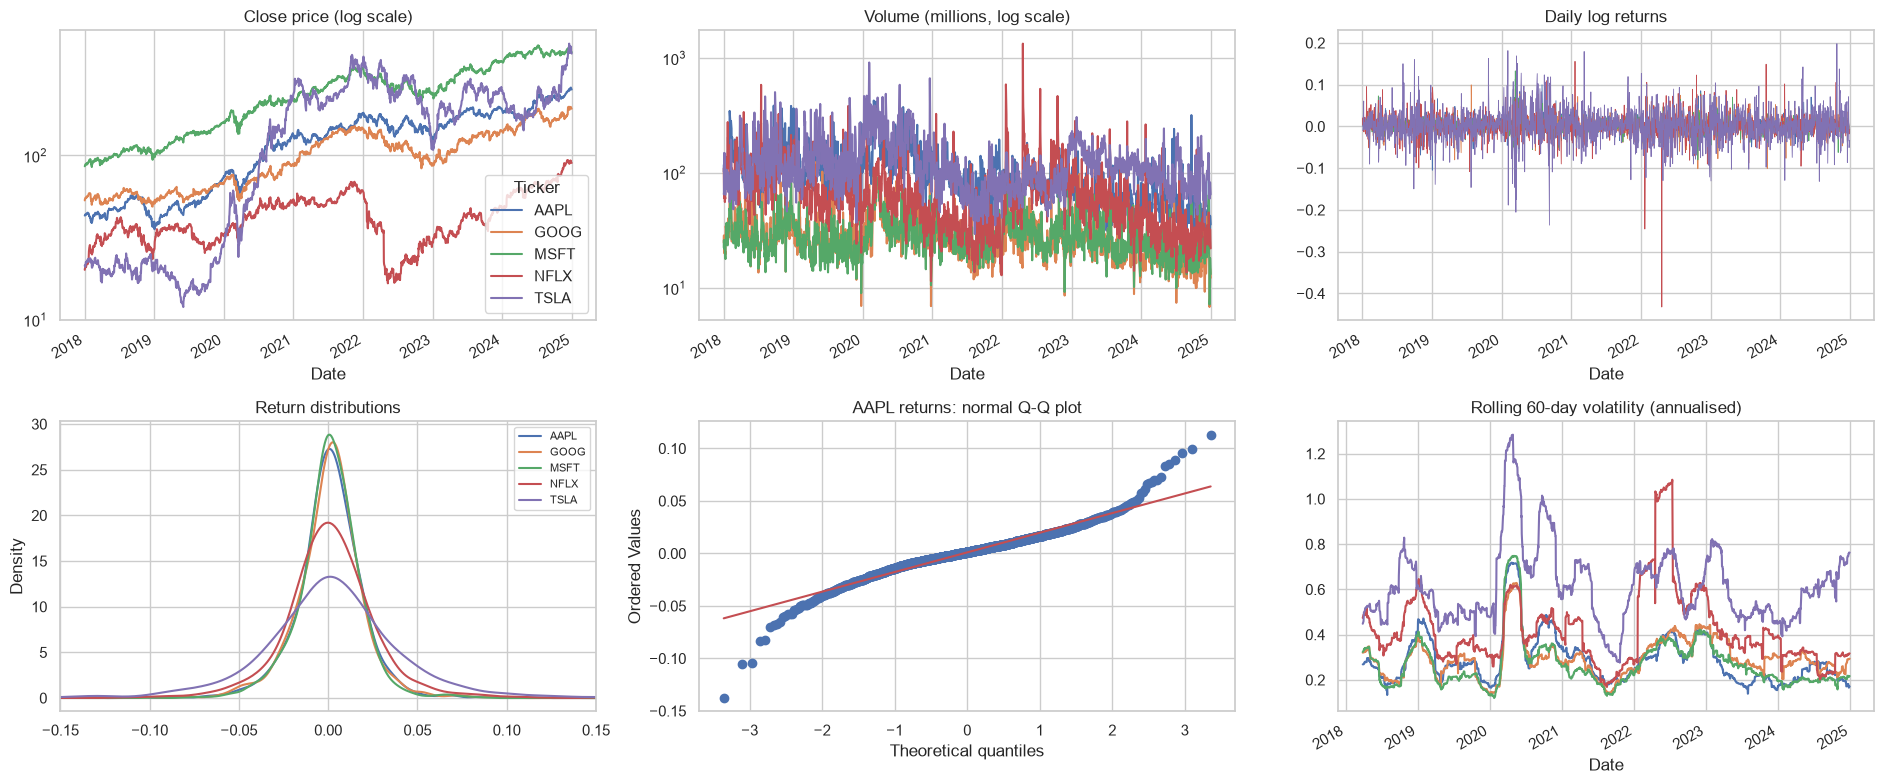

In [2]:
ret = np.log(close).diff().dropna(); big = ret.abs().max()
print("most negative daily log return per stock:", {t: round(float(ret[t].min()), 3) for t in T})
print(ret.describe().round(4).T[["mean", "std", "min", "max"]].to_string())
print("excess kurtosis of daily returns (0 for a normal distribution):", ret.kurt().round(1).to_dict())
fig, ax = plt.subplots(2, 3, figsize=(19, 8))
close.plot(ax=ax[0, 0], logy=True); ax[0, 0].set_title("Close price (log scale)")
(vol / 1e6).plot(ax=ax[0, 1], logy=True, legend=False); ax[0, 1].set_title("Volume (millions, log scale)")
ret.plot(ax=ax[0, 2], legend=False, lw=.6); ax[0, 2].set_title("Daily log returns")
for t, c in zip(T, sns.color_palette(n_colors=5)): ret[t].plot.kde(ax=ax[1, 0], label=t, color=c)
ax[1, 0].set_xlim(-.15, .15); ax[1, 0].set_title("Return distributions"); ax[1, 0].legend(fontsize=8)
stats.probplot(ret["AAPL"], plot=ax[1, 1]); ax[1, 1].set_title("AAPL returns: normal Q-Q plot")
ret.rolling(60).std().mul(np.sqrt(252)).plot(ax=ax[1, 2], legend=False); ax[1, 2].set_title("Rolling 60-day volatility (annualised)")
plt.tight_layout(); plt.show()

**Reading it.** 1,760 trading days for five stocks. Returns are far from a bell curve: the **excess kurtosis** (0 for a normal distribution) is 3.6 to 7.2 for four of the stocks and **35 for Netflix**, whose worst day was a one-day log return of -0.43 (a fall of about 35%). Volatility moves in clusters (the bottom-right panel: calm 2019, turbulent 2020 and 2022), and the Q-Q plot shows heavy tails on both sides. These three facts (heavy tails, changing volatility, huge daily price swings) drive everything that follows: "a normal distribution with constant spread" is the wrong model.

## 3. What does the reference's rule flag?
Global z-score of the **price level** (and of volume) with |z| > 2, as in the reference, here on all seven years.

share of days flagged by |z|>2 -> price level: {'AAPL': 0.0, 'GOOG': 0.0, 'MSFT': 0.0, 'NFLX': 5.1, 'TSLA': 0.0} | volume: {'AAPL': 4.2, 'GOOG': 4.7, 'MSFT': 4.7, 'NFLX': 3.4, 'TSLA': 5.1}
number of separate runs of flagged days in the price rule: {'AAPL': 0, 'GOOG': 0, 'MSFT': 0, 'NFLX': 6, 'TSLA': 0} (a handful of long stretches, not isolated events)


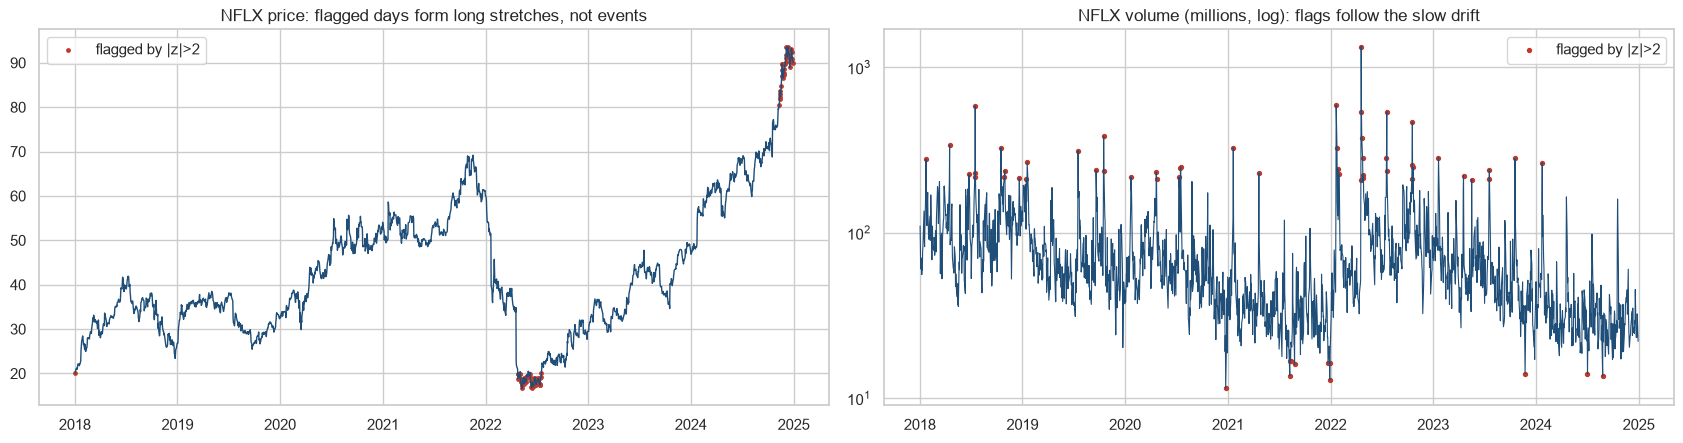

In [3]:
zp = (np.log(close) - np.log(close).mean()) / np.log(close).std(); zv = (np.log(vol) - np.log(vol).mean()) / np.log(vol).std()
flag_p, flag_v = (zp.abs() > 2), (zv.abs() > 2)
print("share of days flagged by |z|>2 -> price level: %s | volume: %s" % ((flag_p.mean() * 100).round(1).to_dict(), (flag_v.mean() * 100).round(1).to_dict()))
runs = {t: int((flag_p[t] & ~flag_p[t].shift(1, fill_value=False)).sum()) for t in T}; print("number of separate runs of flagged days in the price rule:", runs, "(a handful of long stretches, not isolated events)")
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6))
t_ = "NFLX"; ax[0].plot(close.index, close[t_], color="#1f4e79", lw=1); ax[0].scatter(close.index[flag_p[t_]], close[t_][flag_p[t_]], s=6, color="#c0392b", label="flagged by |z|>2"); ax[0].set_title(f"{t_} price: flagged days form long stretches, not events"); ax[0].legend()
ax[1].plot(vol.index, vol["NFLX"] / 1e6, color="#1f4e79", lw=.8); ax[1].scatter(vol.index[flag_v["NFLX"]], vol["NFLX"][flag_v["NFLX"]] / 1e6, s=8, color="#c0392b", label="flagged by |z|>2"); ax[1].set_yscale("log"); ax[1].set_title("NFLX volume (millions, log): flags follow the slow drift"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it.** The reference's price-level rule flags **0% of days for AAPL, GOOG, MSFT and TSLA** and 5.1% of days for NFLX, in 6 separate stretches. A z-score of a *price level* measures how far a price is from its seven-year average, i.e. it detects long-term trends (a stock that rose or fell a lot), not unusual days. Its volume rule flags 3.4-5.1% of days (about one day in twenty, as any |z| > 2 rule does under a bell curve), but because volume drifts slowly, the flagged days come in long runs (right panel) rather than isolated events. Neither flags the days a trader would call anomalies.

## 4. Detectors on returns
For each day t, five anomaly scores (higher = more unusual); only data up to and including day t are used (rolling statistics use the *previous* days):
1. **Global z of returns** (the reference's idea applied to the stationary quantity).
2. **Rolling z (60 days):** return divided by the standard deviation of the previous 60 returns.
3. **Robust z (60 days):** (return - median) / (1.4826 x MAD) over the previous 60 days; not inflated by earlier outliers.
4. **EWMA volatility z:** return / volatility estimated with exponentially weighted variance (decay 0.94, as in RiskMetrics) from the previous days.
5. **Isolation Forest** on 4 features of the day (return, absolute return, high-low range, log-volume change): an unsupervised ML detector.

In [4]:
def scores_for(r, rng_, lv):
    '''r: Series of daily log returns; rng_: high-low range / close; lv: log volume (aligned). Returns DataFrame of anomaly scores.'''
    s = pd.DataFrame(index=r.index)
    s["global z"] = ((r - r.mean()) / r.std()).abs()
    s["rolling z (60d)"] = ((r - r.shift(1).rolling(60).mean()) / r.shift(1).rolling(60).std()).abs()
    med = r.shift(1).rolling(60).median(); mad = (r.shift(1) - med).abs().rolling(60).median(); s["robust z (60d MAD)"] = ((r - med) / (1.4826 * mad + 1e-9)).abs()
    ew = (r.shift(1) ** 2).ewm(alpha=1 - 0.94, adjust=False).mean().pipe(np.sqrt); s["EWMA volatility z"] = (r / (ew + 1e-9)).abs()
    X = pd.DataFrame({"r": r, "ar": r.abs(), "range": rng_, "dlv": lv.diff()}).fillna(0)
    iso = IsolationForest(n_estimators=200, contamination="auto", random_state=0).fit(X); s["Isolation Forest"] = -iso.score_samples(X)
    s.iloc[:60] = np.nan                                   # warm-up: rolling and EWMA statistics are not reliable in the first 60 days
    return s
rngx = ((hi - lo) / close).reindex(ret.index); lvx = np.log(vol).reindex(ret.index)
S = {t: scores_for(ret[t], rngx[t], lvx[t]) for t in T}
print({m: round(float(np.mean([S[t][m].dropna().gt(S[t][m].dropna().quantile(.99)).mean() for t in T])) * 100, 2) for m in S["AAPL"].columns}, "% of days flagged at the top-1% threshold (by construction about 1%)")

{'global z': 1.0, 'rolling z (60d)': 1.0, 'robust z (60d MAD)': 1.04, 'EWMA volatility z': 1.0, 'Isolation Forest': 1.0} % of days flagged at the top-1% threshold (by construction about 1%)


## 5. The test: plant anomalies of known size and see who finds them
For each stock I add **60 jumps** at random days (return shifted by +/- k x the stock's recent volatility, k = 3, 4, 6, 8; each jump persists, like real news). Detectors are re-run on the modified series. Two metrics, with the 60 planted days as positives and all other days as negatives: **AUC** (how well scores rank planted above normal days) and **recall@60** (flag the 60 highest-scoring days, as many as were planted; the share of planted jumps among them, which here equals the precision). The remaining real extreme days count as negatives, so the numbers are slightly pessimistic for every method alike.

AUC (mean of 5 stocks, 60 planted jumps each):
k_sigma                 3      4      6      8
detector                                      
EWMA volatility z   0.961  0.987  0.996  0.997
Isolation Forest    0.941  0.968  0.987  0.992
global z            0.950  0.980  0.996  0.999
robust z (60d MAD)  0.935  0.955  0.981  0.976
rolling z (60d)     0.957  0.982  0.996  0.997

recall of planted jumps when exactly 60 days (as many as were planted) are flagged:
k_sigma                3     4     6     8
detector                                  
EWMA volatility z   55.0  71.0  83.0  87.0
Isolation Forest    36.0  46.0  63.0  72.0
global z            46.0  64.0  83.0  91.0
robust z (60d MAD)  49.0  64.0  84.0  92.0
rolling z (60d)     51.0  65.0  82.0  86.0


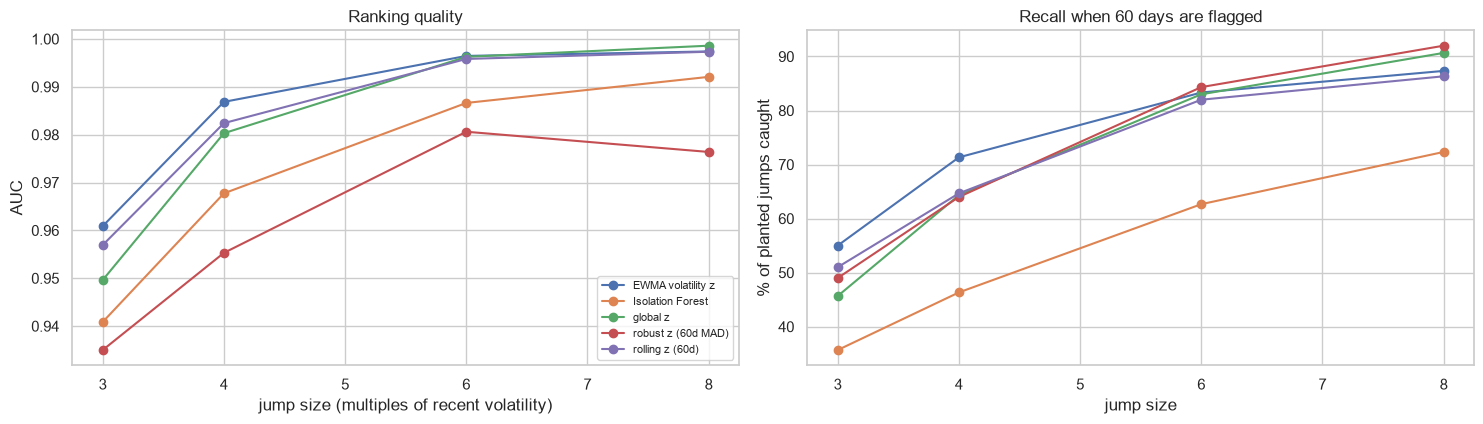

In [5]:
def inject(t, k, seed):
    r = ret[t].copy(); ew = (r.shift(1) ** 2).ewm(alpha=1 - 0.94, adjust=False).mean().pipe(np.sqrt); rs = np.random.RandomState(seed)
    days = rs.choice(np.arange(80, len(r) - 5), 60, replace=False); sgn = rs.choice([-1, 1], 60); lab = np.zeros(len(r), bool); lab[days] = True
    r.iloc[days] = r.iloc[days].to_numpy() + sgn * k * ew.iloc[days].to_numpy(); return r, lab
rows = []
for k in (3, 4, 6, 8):
    acc = {}
    for t in T:
        r2, lab = inject(t, k, seed=hash(t) % 1000 + k); s2 = scores_for(r2, rngx[t], lvx[t])
        for m in s2.columns:
            sc = s2[m].fillna(0); thr = sc.quantile(.99); acc.setdefault(m, []).append((roc_auc_score(lab, sc), (sc[lab] >= sc.nlargest(60).min()).mean()))
    for m, v in acc.items(): rows.append([k, m, np.mean([a for a, _ in v]), np.mean([b for _, b in v])])
inj = pd.DataFrame(rows, columns=["k_sigma", "detector", "AUC", "recall@60"])
A = inj.pivot(index="detector", columns="k_sigma", values="AUC"); Rc = inj.pivot(index="detector", columns="k_sigma", values="recall@60")
print("AUC (mean of 5 stocks, 60 planted jumps each):"); print(A.round(3).to_string()); print("\nrecall of planted jumps when exactly 60 days (as many as were planted) are flagged:"); print((Rc * 100).round(0).to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for m in A.index: ax[0].plot(A.columns, A.loc[m], "o-", label=m); ax[1].plot(Rc.columns, Rc.loc[m] * 100, "o-", label=m)
ax[0].set_xlabel("jump size (multiples of recent volatility)"); ax[0].set_ylabel("AUC"); ax[0].set_title("Ranking quality"); ax[1].set_xlabel("jump size"); ax[1].set_ylabel("% of planted jumps caught"); ax[1].set_title("Recall when 60 days are flagged"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading it (planted jumps; AUC and recall@60 averaged over the 5 stocks).**
* **AUC is high for every detector (0.94-1.00)**: any of them ranks a planted jump above a typical day. The more informative number is **recall@60**: if the detector may flag as many days as were planted, how many are right?
* **For small jumps (3x the recent volatility) the volatility-adjusted EWMA z-score is best (55% found)**, ahead of the rolling z (51%), the robust z (49%), the global z (46%) and the Isolation Forest (36%). For larger jumps (6-8x) the methods converge (82-92% for all but the Isolation Forest, which finds only 63-72%): a huge move is easy for any rule. The global z of returns does as well as the adaptive ones at 8x (91%) because it simply needs a big number.
* **The Isolation Forest, an ML method, is the weakest here.** It uses four features at once and has no knowledge that a return of -3% is a lot in a quiet month and little in a turbulent one.
* Caveat: genuine extreme days present in the real data are counted as "false alarms" for every method, so all recall figures are slightly pessimistic; and the real anomalies are not jumps added to a clean series.

**Volume bursts.** The same test for volume: multiply volume on 60 random days by 3 or 5; detectors: global z of log volume (the reference), rolling z of log volume (previous 60 days), and Isolation Forest on [return, range, log-volume change].

In [6]:
def vol_scores(lv_, r_, rg_):
    s = pd.DataFrame(index=lv_.index); s["global z (reference)"] = ((lv_ - lv_.mean()) / lv_.std()).abs()
    s["rolling z (60d)"] = ((lv_ - lv_.shift(1).rolling(60).mean()) / lv_.shift(1).rolling(60).std()).abs()
    X = pd.DataFrame({"r": r_, "range": rg_, "dlv": lv_.diff()}).fillna(0); s["Isolation Forest"] = -IsolationForest(n_estimators=200, random_state=0).fit(X).score_samples(X); return s
rows = []
for f in (3, 5):
    acc = {}
    for t in T:
        lv2 = lvx[t].copy(); rs = np.random.RandomState(hash(t) % 1000 + f); days = rs.choice(np.arange(80, len(lv2) - 5), 60, replace=False); lab = np.zeros(len(lv2), bool); lab[days] = True; lv2.iloc[days] += np.log(f)
        s2 = vol_scores(lv2, ret[t], rngx[t])
        for m in s2.columns: sc = s2[m].fillna(0); acc.setdefault(m, []).append((roc_auc_score(lab, sc), (sc[lab] >= sc.nlargest(60).min()).mean()))
    for m, v in acc.items(): rows.append([f"x{f}", m, np.mean([a for a, _ in v]), np.mean([b for _, b in v]) * 100])
VB = pd.DataFrame(rows, columns=["volume multiplied by", "detector", "AUC", "recall@60_%"]); print(VB.round(2).to_string(index=False))

volume multiplied by             detector  AUC  recall@60_%
                  x3 global z (reference) 0.87        41.33
                  x3      rolling z (60d) 0.95        50.00
                  x3     Isolation Forest 0.87        12.33
                  x5 global z (reference) 0.98        74.67
                  x5      rolling z (60d) 0.99        76.00
                  x5     Isolation Forest 0.92        16.33


**Reading it.** For volume bursts (a day's volume multiplied by 3 or 5) the **rolling z-score of log volume** is best (50% found at 3x, 76% at 5x), the reference's global z is close behind at 5x (75%) but weaker at 3x (41%), because slow drifts in volume make a fixed average a poor yardstick. The Isolation Forest finds 12-16%. With a 3x burst, many real days already have 3x the previous volume, so even the best method only catches half.

## 6. Calibrating the threshold: are returns "normal"?
A rule like "|z| > 3" assumes a bell curve, under which about 0.27% of days exceed 3 standard deviations. Returns have heavier tails; I count the actual exceedances of the EWMA z-score.

In [7]:
z = pd.DataFrame({t: S[t]["EWMA volatility z"] for t in T}).dropna()
tab = pd.DataFrame({f"|z| > {c}": (z > c).mean() * 100 for c in (2, 3, 4, 5)}).T; tab["normal distribution expects"] = [2 * stats.norm.sf(c) * 100 for c in (2, 3, 4, 5)]
print("share of days with EWMA z beyond the threshold (%):"); print(tab.round(3).to_string())

share of days with EWMA z beyond the threshold (%):
          AAPL   GOOG   MSFT   NFLX   TSLA  normal distribution expects
|z| > 2  5.592  5.886  6.062  4.885  5.886                        4.550
|z| > 3  1.413  1.648  1.118  1.530  1.707                        0.270
|z| > 4  0.412  0.530  0.177  0.765  0.589                        0.006
|z| > 5  0.235  0.353  0.118  0.530  0.353                        0.000


**Reading it.** A bell-curve rule "|z| > 3" would flag 0.27% of days. The EWMA-scaled returns exceed 3 on **1.1-1.7% of days (4 to 6 times more)**, exceed 4 on 0.18-0.77% of days against 0.006% under a normal distribution (30 to 100 times more), and exceed 5 on 0.12-0.53%. So thresholds taken from normal-distribution tables produce far more alarms than advertised; the threshold should be set from the empirical tail (an alarm budget), as I do next (|z| > 4.5, which flags 0.39% of stock-days).

## 7. What does the best detector find in the real data?
Use the EWMA z-score with threshold |z| > 4.5. A day flagged for **three or more stocks at once** is a *market-wide* anomaly; a day flagged for one is *idiosyncratic* (company news, earnings...).

flagged stock-days: 33 of 8495 (0.39%) | days with >=3 stocks flagged: 0 | single-stock flagged days: 31



top 12 flagged days:
      date stock  return_%  ewma_z
2022-04-20  NFLX    -43.26   15.47
2022-01-21  NFLX    -24.58   13.56
2019-07-26  GOOG      9.94    8.99
2019-04-30  GOOG     -8.01    8.46
2023-10-19  NFLX     14.89    8.13
2021-01-20  NFLX     15.58    7.86
2023-10-25  GOOG    -10.09    7.45
2024-10-18  NFLX     10.51    7.29
2019-10-24  TSLA     16.27    7.29
2019-07-18  NFLX    -10.84    7.27
2024-10-31  MSFT     -6.24    6.76
2021-10-25  TSLA     11.92    6.76

market-wide days (>=3 stocks flagged): []
flagged stock-days in 15 Feb-30 Apr 2020: 0 of 33 total (0%)
for comparison, the GLOBAL return z-score (|z| > 4) flags 44 stock-days in total, of which 21 (48%) fall in the same 11 weeks; days with >=3 stocks flagged by it: 3


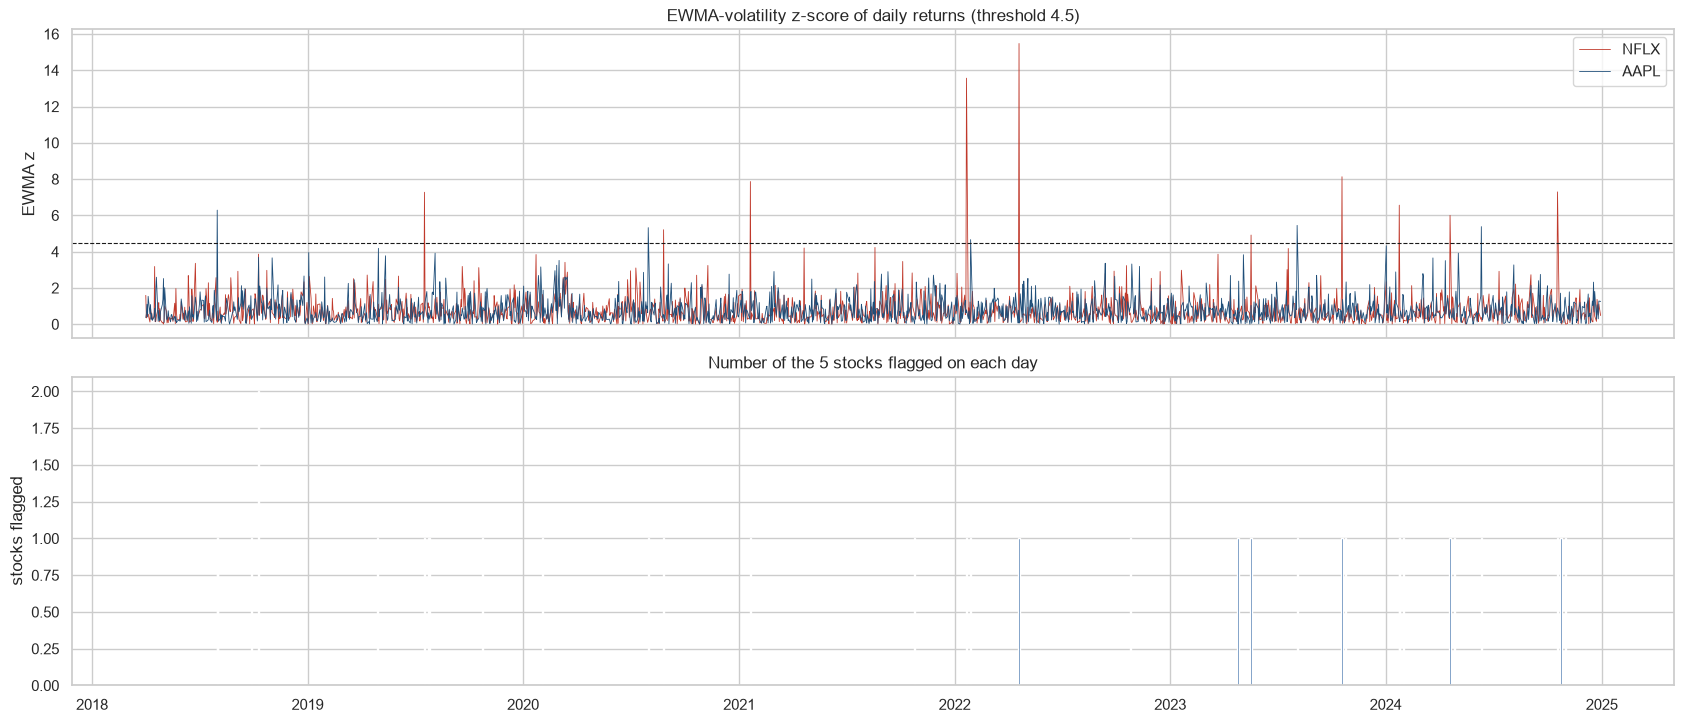

In [8]:
TH = 4.5; flag = z > TH; nflag = flag.sum(1)
print("flagged stock-days: %d of %d (%.2f%%) | days with >=3 stocks flagged: %d | single-stock flagged days: %d" % (flag.values.sum(), flag.size, flag.values.mean() * 100, (nflag >= 3).sum(), (nflag == 1).sum()))
top = pd.DataFrame([(d.date(), t, ret.loc[d, t] * 100, z.loc[d, t]) for d in z.index for t in T if flag.loc[d, t]], columns=["date", "stock", "return_%", "ewma_z"]).sort_values("ewma_z", ascending=False)
print("\ntop 12 flagged days:"); print(top.head(12).round(2).to_string(index=False))
mk = nflag[nflag >= 3]; print("\nmarket-wide days (>=3 stocks flagged):", [str(d.date()) for d in mk.index])
mid = z.loc["2020-02-15":"2020-04-30"]; print("flagged stock-days in 15 Feb-30 Apr 2020: %d of %d total (%.0f%%)" % ((mid > TH).values.sum(), flag.values.sum(), (mid > TH).values.sum() / flag.values.sum() * 100))
gz = ((ret - ret.mean()) / ret.std()).abs(); gflag = gz > 4; gm = gflag.loc["2020-02-15":"2020-04-30"]
print("for comparison, the GLOBAL return z-score (|z| > 4) flags %d stock-days in total, of which %d (%.0f%%) fall in the same 11 weeks; days with >=3 stocks flagged by it: %d" % (gflag.values.sum(), gm.values.sum(), gm.values.sum() / gflag.values.sum() * 100, (gflag.sum(1) >= 3).sum()))
fig, ax = plt.subplots(2, 1, figsize=(17, 7.4), sharex=True)
for t_, c in [("NFLX", "#c0392b"), ("AAPL", "#1f4e79")]: ax[0].plot(z.index, z[t_], lw=.6, color=c, label=t_)
ax[0].axhline(TH, color="k", ls="--", lw=.8); ax[0].set_ylabel("EWMA z"); ax[0].legend(); ax[0].set_title("EWMA-volatility z-score of daily returns (threshold 4.5)")
ax[1].bar(nflag.index, nflag.values, width=2, color="#3b6ea8"); ax[1].set_ylabel("stocks flagged"); ax[1].set_title("Number of the 5 stocks flagged on each day")
plt.tight_layout(); plt.show()

**Reading it.**
* At |z| > 4.5 the detector flags **33 of 8,495 stock-days (0.39%)**, 31 of them single-stock days and none on which three or more of the stocks are flagged together.
* The top flags are large, one-stock surprises: **Netflix on 2022-04-20 (-43% log return, z = 15.5; about -35%)** and **2022-01-21 (-25%, z = 13.6)**, Google on 2019-07-26 (+9.9%) and 2019-04-30 (-8.0%), Netflix on 2023-10-19 (+14.9%), 2021-01-20 (+15.6%) and 2024-10-18 (+10.5%), Tesla on 2019-10-24 (+16.3%) and 2021-10-25 (+11.9%). I do not have a news feed in this notebook; the next section checks the dates against earnings announcements.
* **None of the flags fall in the February-April 2020 crash**: the detector measures a return against the volatility of the *previous days*, which rose quickly in March 2020, so daily moves were large but not surprising *given* the turbulence. The simpler global z-score of returns does the opposite: 21 of its 44 flagged stock-days (48%) fall in those 11 weeks and 3 days see three or more stocks flagged. Neither is "right": **the definition of an anomaly (a rare level of movement, or a surprise relative to the recent regime) is a modelling choice** that decides what is found.

## 8. Earnings dates: do idiosyncratic flags line up with scheduled news?

In [9]:
earn = {}
try:
    import yfinance as yf
    for t in T:
        ed = yf.Ticker(t).get_earnings_dates(limit=40)
        if ed is not None and len(ed): earn[t] = pd.DatetimeIndex(ed.index.tz_localize(None).normalize()).unique()
except Exception as e:
    print("earnings dates not available:", str(e)[:80])
if earn:
    rows = []
    for t in T:
        if t not in earn: continue
        e = earn[t][(earn[t] >= z.index[0]) & (earn[t] <= z.index[-1])]; nxt = pd.DatetimeIndex([z.index[z.index.searchsorted(d)] for d in e if z.index.searchsorted(d) < len(z)]) if len(e) else pd.DatetimeIndex([])
        near = set(nxt) | set(z.index[np.clip(z.index.searchsorted(nxt) + 1, 0, len(z) - 1)]) if len(nxt) else set()
        f = z.index[flag[t]]; rows.append([t, len(e), len(f), sum(d in near for d in f), flag[t][list(near)].mean() * 100 if near else np.nan, flag[t].mean() * 100])
    ER = pd.DataFrame(rows, columns=["stock", "earnings dates", "flagged days", "flagged days on/after an earnings date", "% of earnings-reaction days flagged", "% of all days flagged"]); print(ER.round(1).to_string(index=False))

stock  earnings dates  flagged days  flagged days on/after an earnings date  % of earnings-reaction days flagged  % of all days flagged
 AAPL              27             5                                       4                                  7.4                    0.3
 GOOG              27             7                                       6                                 11.1                    0.4
 MSFT              27             3                                       2                                  3.7                    0.2
 NFLX              27            10                                       8                                 14.8                    0.6
 TSLA              27             8                                       5                                  9.3                    0.5


**Reading it.** Earnings dates from `yfinance` (27 per stock over the period; I did not check them against company releases): **25 of the 33 flagged days (76%) fall on an earnings day or the next trading day**, although those two days are only about 3% of all trading days. Netflix: 8 of 10 flags, Google 6 of 7, Tesla 5 of 8, Apple 4 of 5, Microsoft 2 of 3. This is independent evidence that the detector finds *news-driven* moves. The detector is conservative: only 4-15% of earnings-reaction days are flagged (most earnings releases move a stock less than 4.5 times its recent daily volatility). The 8 flags that are not near earnings are candidates for other news (I did not investigate them).

## 9. Save the detector

In [10]:
iso_models = {t: IsolationForest(n_estimators=200, random_state=0).fit(pd.DataFrame({"r": ret[t], "ar": ret[t].abs(), "range": rngx[t], "dlv": lvx[t].diff()}).fillna(0)) for t in T}
joblib.dump({"iso": iso_models, "ewma_decay": 0.94, "threshold": TH}, "model/anomaly_detectors.joblib")
top.head(60).to_csv("model/flagged_days.csv", index=False)
json.dump({"auc_planted": A.round(3).to_dict("index"), "recall_1pct": (Rc * 100).round(1).to_dict("index"), "tail_table": tab.round(3).to_dict("index"), "flags": int(flag.values.sum()), "market_wide_days": [str(d.date()) for d in mk.index]}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['anomaly_detectors.joblib', 'flagged_days.csv', 'meta.json']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Quantity analysed | z-score of the *price level* and volume over the whole year | daily *returns*, scaled by recent volatility; volume vs its recent history |
| What the rule flags | 0-5% of days, long stretches that follow trends | isolated surprises: 33 stock-days of 8,495 |
| Validation | none | planted jumps (3-8x volatility) and volume bursts; recall@60: EWMA 55% for 3x jumps vs global z 46%, Isolation Forest 36% |
| Threshold | |z| > 2 from a bell curve | empirical: |z| > 3 happens 4-6x more often than a bell curve says; alarm budget 0.39% |
| Real-data check | none | 76% of flags fall on earnings days (3% of days); March 2020 is not flagged by the adaptive detector, but is by the global rule |

**What I learned.** (1) Choose the quantity before the rule: z-scores of price levels measure trends, not anomalies. (2) With no labels, plant anomalies of known size to compare detectors, and state the recall at a fixed number of alarms. (3) A simple volatility-adjusted score beat the Isolation Forest here. (4) "Anomaly" depends on the reference regime: against the long-run average, March 2020 is the anomaly; against the previous weeks it is not.

**Limits.** Five large US stocks, 7 years; planted anomalies are one kind (a persistent jump; a volume multiplier); earnings dates unverified; a threshold of 4.5 is a choice; no intraday data. **Next step:** a GARCH model for the volatility, a test on a stock with fewer news events, and a labelled set of known events.